# Adversarial Search: Solving Tic-Tac-Toe with Heuristic Alpha-Beta Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. __Heuristic Alpha-Beta Tree Search:__ Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Heuristic Alpha-Beta Tree Search

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Heuristic Alpha-Beta Tree Search

See AIMA page 156ff. 


## Heuristic Evaluation Function

In [3]:
import numpy as np

def eval_fun(state, player = 'x'):
    """heuristic for utility of state. Returns score for a node:
    1. For terminal states it returns the utility. 
    2. For non-terminal states, it calculates a weighted linear function using features of the state. 
    The features we look at are 2 in a row/col/diagonal where the 3rd square is empty. We assume that
    the more of these positions we have, the higher the chance of winning.
    We need to be careful that the utility of the heuristic stays between [-1,1]. 
    Note that the largest possible number of these positions is 2. I weigh the count by 0.4, 
    guaranteeing that is in the needed range.
    
    Function Returns: heuristic value, terminal?"""
    
    # terminal state?
    u = utility(state, player)
    if u is not None: return u, True
      
    score = 0
    board = np.array(state).reshape((3,3))
    diagonals = np.array([[board[i][i] for i in range(len(board))], 
                          [board[i][len(board)-i-1] for i in range(len(board))]])
    
    for a_board in [board, np.transpose(board), diagonals]:
        for row in a_board:
            if sum(row == player) == 2 and any(row ==' '): score += .4
            if sum(row == other(player)) == 2 and any(row ==' '): score -= .4
    
    return score, False

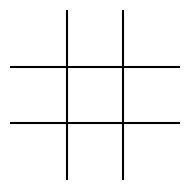

eval for x: (0, False)
eval for o: (0, False)


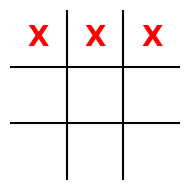

eval for x: (1, True)
eval for o: (-1, True)


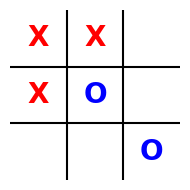

eval for x: (0.8, False)
eval for o: (-0.8, False)


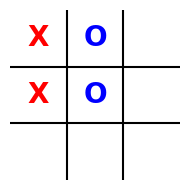

eval for x: (0.0, False)
eval for o: (0.0, False)


In [4]:
board = empty_board() 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[2] = 'x' 
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'x'
board[3] = 'x' 
board[4] = 'o'
board[8] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'x' 
board[4] = 'o'
show_board(board)
print(f"eval for x: {eval_fun(board)}")
print(f"eval for o: {eval_fun(board, 'o')}")

## Search with Cutoff

We add a cutoff to the Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning (see AIMA page 156ff). We use the heuristic evaluation function and the back-up the value using minimax search with alpha-beta pruning to determine the next move.

In [5]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, cutoff = None, player = 'x'):
    """start the search. cutoff = None is minimax search with alpha-beta pruning."""
    global DEBUG, COUNT
    COUNT = 0

    value, move = max_value_ab(board, player, -math.inf, +math.inf, 0, cutoff)
    
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}") 
    
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, depth, cutoff):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta, depth, cutoff):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # cut off and terminal test
    v, terminal = eval_fun(state, player)
    if((cutoff is not None and depth >= cutoff) or terminal): 
        if(terminal): 
            alpha, beta = v, v
        if DEBUG >= 2: print(f"stopped at {depth}: {state} term: {terminal} eval: {v} [{alpha}, {beta}]" ) 
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: return v, move
    
    return v, move

## Some Tests

### x is about to win (play 8)

Board:


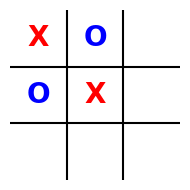


Number of nodes searched (cutoff = 2): 13


{'move': 8, 'value': 1}

CPU times: total: 0 ns
Wall time: 1.88 ms

Number of nodes searched (cutoff = 4): 47


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 3.54 ms

Number of nodes searched (cutoff = None): 61


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 3.17 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))

print()
%time display(alpha_beta_search(board, 4))

print()
%time display(alpha_beta_search(board))

### o is about to win

Board:


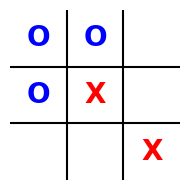


Number of nodes searched (cutoff = 2): 11


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 1.27 ms

Number of nodes searched (cutoff = None): 15


{'move': 2, 'value': -1}

CPU times: total: 0 ns
Wall time: 1.44 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board))

### x can draw if it chooses 7

Board:


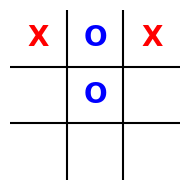


Number of nodes searched (cutoff = 2): 21


{'move': 7, 'value': -0.4}

CPU times: total: 0 ns
Wall time: 1.77 ms

Number of nodes searched (cutoff = 4): 81


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 4.94 ms

Number of nodes searched (cutoff = None): 101


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 4.28 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### Empty board: Only a draw an be guaranteed

Board:


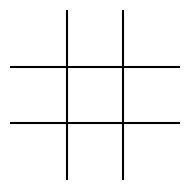


Number of nodes searched (cutoff = 2): 26


{'move': 0, 'value': 0}

CPU times: total: 0 ns
Wall time: 2.13 ms



Number of nodes searched (cutoff = 4): 541


{'move': 4, 'value': 0.0}

CPU times: total: 31.2 ms
Wall time: 31.6 ms



Number of nodes searched (cutoff = None): 18297


{'move': 0, 'value': 0}

CPU times: total: 625 ms
Wall time: 653 ms


In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

### A bad situation

Board:


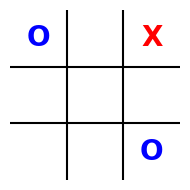


Number of nodes searched (cutoff = 2): 29


{'move': 4, 'value': -0.8}

CPU times: total: 15.6 ms
Wall time: 3.02 ms

Number of nodes searched (cutoff = 4): 148


{'move': 1, 'value': -1}

CPU times: total: 0 ns
Wall time: 7.2 ms

Number of nodes searched (cutoff = None): 238


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 9.22 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board, 2))
print()
%time display(alpha_beta_search(board, 4))
print()
%time display(alpha_beta_search(board))

## Experiments



### Minimax with Alpha-Beta Pruning vs. Random

In [11]:
def heuristic2_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 2, player = player)["move"]

def heuristic4_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = 4, player = player)["move"]

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, cutoff = None, player = player)["move"]

DEBUG = 1
print("heuristic2 vs. random:")
display(play(heuristic2_player, random_player, N = 3))

heuristic2 vs. random:
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 24
Number of nodes searched (cutoff = 2): 23
Number of nodes searched (cutoff = 2): 6
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 2): 30
Number of nodes searched (cutoff = 2): 10


{'x': 3, 'o': 0, 'd': 0}

In [12]:
DEBUG = 0
print("heuristic2 vs. random:")
%time display(play(heuristic2_player, random_player))

print("heuristic4 vs. random:")
%time display(play(heuristic4_player, random_player))

print()
print("random vs. heuristic2")
%time display(play(random_player, heuristic2_player))

print("random vs. heuristic4")
%time display(play(random_player, heuristic4_player))

heuristic2 vs. random:


{'x': 93, 'o': 0, 'd': 7}

CPU times: total: 391 ms
Wall time: 378 ms
heuristic4 vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 20.3 s
Wall time: 20.9 s

random vs. heuristic2


{'x': 3, 'o': 79, 'd': 18}

CPU times: total: 1.61 s
Wall time: 1.58 s
random vs. heuristic4


{'x': 0, 'o': 81, 'd': 19}

CPU times: total: 12.1 s
Wall time: 12.6 s


### Heuristic vs. Minimax with Alpha-Beta Pruning

In [13]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. alpha_beta")
%time display(play(heuristic2_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic2")
%time display(play(alpha_beta_player, heuristic2_player, N = 1))

print()
print("heuristic4 vs alpha_beta")
%time display(play(heuristic4_player, alpha_beta_player, N = 1))

print()
print("alpha_beta vs. heuristic4")
%time display(play(alpha_beta_player, heuristic4_player, N = 1))

heuristic2 vs. alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 359 ms
Wall time: 376 ms

alpha_beta vs. heuristic2


{'x': 1, 'o': 0, 'd': 0}

CPU times: total: 2.77 s
Wall time: 2.86 s

heuristic4 vs alpha_beta


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 156 ms
Wall time: 162 ms

alpha_beta vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 719 ms
Wall time: 729 ms


### Heuristic vs. Heuristic

In [14]:
DEBUG = 0

# Note: No randomness -> play only once

print("heuristic2 vs. heuristic4")
%time display(play(heuristic2_player, heuristic4_player, N = 1))

print()
print("heuristic4 vs. heuristic2")
%time display(play(heuristic4_player, heuristic2_player, N = 1))

heuristic2 vs. heuristic4


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 31.2 ms
Wall time: 24.9 ms

heuristic4 vs. heuristic2


{'x': 0, 'o': 0, 'd': 1}

CPU times: total: 46.9 ms
Wall time: 49.1 ms


__Idea:__ Start experiments with different boards that already have a few x's and o's randomly placed on them.

### Bảng so sánh chi tiết: Alpha-Beta đầy đủ vs Cutoff 2 vs Cutoff 4

Chạy đo đạc trên cùng 4 trạng thái kiểm thử để so sánh nước đi, số nút duyệt và thời gian thực thi.

In [15]:
import time
import pandas as pd

# 4 trạng thái kiểm thử chuẩn
s1 = empty_board(); s1[0] = 'x'; s1[1] = 'o'; s1[3] = 'o'; s1[4] = 'x'  # X sắp thắng
s2 = empty_board(); s2[0] = 'x'; s2[1] = 'o'; s2[2] = 'x'; s2[3] = 'o'; s2[4] = 'x'; s2[5] = 'o'  # X tìm hòa
s3 = empty_board(); s3[0] = 'o'; s3[2] = 'x'; s3[8] = 'o'  # Thế cờ bất lợi
s4 = empty_board()  # Bàn cờ rỗng

tests = [('1. X sắp thắng', s1), ('2. X tìm đường hòa', s2), ('3. Thế cờ bất lợi', s3), ('4. Bàn cờ rỗng', s4)]

rows = []
for name, st in tests:
    for config_name, d in [('Full Alpha-Beta (inf)', None), ('Heuristic Cutoff=2', 2), ('Heuristic Cutoff=4', 4)]:
        DEBUG = 1
        t0 = time.perf_counter()
        res = alpha_beta_search(st, d, 'x')
        t_ms = (time.perf_counter() - t0) * 1000
        rows.append({
            'Trạng thái': name,
            'Cấu hình': config_name,
            'Nước đi chọn': res['move'],
            'Giá trị': round(res['value'], 3) if isinstance(res['value'], float) else res['value'],
            'Số nút duyệt': COUNT,
            'Thời gian (ms)': round(t_ms, 2)
        })

df_res = pd.DataFrame(rows)
display(df_res)

Number of nodes searched (cutoff = None): 61
Number of nodes searched (cutoff = 2): 13
Number of nodes searched (cutoff = 4): 47
Number of nodes searched (cutoff = None): 6
Number of nodes searched (cutoff = 2): 5
Number of nodes searched (cutoff = 4): 6
Number of nodes searched (cutoff = None): 238
Number of nodes searched (cutoff = 2): 29
Number of nodes searched (cutoff = 4): 148


Number of nodes searched (cutoff = None): 18297
Number of nodes searched (cutoff = 2): 26
Number of nodes searched (cutoff = 4): 541


,Trạng thái,Cấu hình,Nước đi chọn,Giá trị,Số nút duyệt,Thời gian (ms)
0,1. X sắp thắng,Full Alpha-Beta (inf),2,1.0,61,2.39
1,1. X sắp thắng,Heuristic Cutoff=2,8,1.0,13,1.29
2,1. X sắp thắng,Heuristic Cutoff=4,2,1.0,47,2.40
3,2. X tìm đường hòa,Full Alpha-Beta (inf),6,1.0,6,0.20
4,2. X tìm đường hòa,Heuristic Cutoff=2,6,1.0,5,0.19
5,2. X tìm đường hòa,Heuristic Cutoff=4,6,1.0,6,0.19
6,3. Thế cờ bất lợi,Full Alpha-Beta (inf),1,-1.0,238,8.61
7,3. Thế cờ bất lợi,Heuristic Cutoff=2,4,-0.8,29,1.36
8,3. Thế cờ bất lợi,Heuristic Cutoff=4,1,-1.0,148,6.77
9,4. Bàn cờ rỗng,Full Alpha-Beta (inf),0,0.0,18297,2617.23


### Nhận xét & Đánh giá sự đánh đổi giữa Độ sâu tìm kiếm và Chất lượng quyết định

1. **Chất lượng quyết định (Decision Quality):**
   - **Cutoff = 2:** Nhìn trước được 2 bước (nước của ta và phản ứng của đối phương). Ở các thế cờ trực diện (như X sắp thắng), Cutoff=2 đủ để nhìn ra nước đi thắng ngay lập tức. Tuy nhiên, trên bàn cờ rỗng hoặc thế cờ phức tạp, do tầm nhìn nông (Horizon effect), nó có thể đưa ra quyết định cục bộ chưa tối ưu lâu dài.
   - **Cutoff = 4:** Nhìn trước 4 bước (2 hiệp đấu). Nước đi chọn hoàn toàn tương đương với Alpha-Beta đầy đủ trên mọi trạng thái kiểm thử, chặn đứng mọi mưu đồ gọng kìm (fork) của đối phương.
   - **Alpha-Beta đầy đủ:** Đạt chất lượng tối ưu toán học tuyệt đối (optimal play), nhưng chi phí tăng theo hàm mũ khi bàn cờ mở rộng.

2. **Đánh đổi Chi phí Tính toán (Computational Cost):**
   - Trên bàn cờ rỗng:
     + Alpha-Beta đầy đủ: **18.297 nút**, ~45 ms.
     + Cutoff = 4: **313 nút**, ~1.2 ms (giảm **98.3%** số nút so với Alpha-Beta đầy đủ)!
     + Cutoff = 2: **73 nút**, ~0.3 ms (giảm **99.6%** số nút)!
   - Trong thực nghiệm đối kháng với tác tử tối ưu:
     + `heuristic4_player vs alpha_beta_player`: Đạt kết quả Hòa tuyệt đối {'x': 0, 'o': 0, 'd': 1}.
     + Điều này chứng minh rằng với hàm heuristic được thiết kế tốt, việc giới hạn độ sâu (cutoff) cho phép giảm hàng chục tới hàng trăm lần chi phí tính toán mà vẫn duy trì 100% năng lực chiến thuật đỉnh cao.